In [1]:
from pathlib import Path
import jax
import jax.numpy as jnp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, Predictive
import arviz as az

import arviz_plots as azp
import arviz_base as azb
import arviz_stats as azs
import xarray as xr

from numpyro.infer import SVI, Trace_ELBO
from numpyro.infer.autoguide import AutoNormal
import numpyro.optim as optim
import time

In [2]:
numpyro.set_host_device_count(4)
sns.set_theme(style="whitegrid")
azp.style.use("arviz-variat")

In [3]:
processed_dir = Path("data/processed")
episodes_df = pd.read_csv(processed_dir / "episodes.csv")
weekly_grid_df = pd.read_csv(processed_dir / "weekly_grid.csv")

episodes_df = episodes_df.sort_values("episode_id").reset_index(drop=True)
episodes_df["ep_idx"] = np.arange(len(episodes_df))

weekly_grid_df = weekly_grid_df.merge(
    episodes_df[["episode_id", "ep_idx"]], on="episode_id", how="left"
).sort_values(["ep_idx", "t"]).reset_index(drop=True)

age_mean, age_std = episodes_df["age"].mean(), episodes_df["age"].std()
dist_mean, dist_std = episodes_df["distance_km"].mean(), episodes_df["distance_km"].std()

model_data = {
    "N_episodes": len(episodes_df),
    "age_z": jnp.asarray((episodes_df["age"] - age_mean) / age_std, dtype=jnp.float32),
    "dist_z": jnp.asarray((episodes_df["distance_km"] - dist_mean) / dist_std, dtype=jnp.float32),
    "promo_friends": jnp.asarray(episodes_df["promo_friends"], dtype=jnp.float32),
    "partners_company": jnp.asarray(episodes_df["partners_company"], dtype=jnp.float32),
    "group_affinity": jnp.asarray(episodes_df["group_affinity"], dtype=jnp.float32),
    "is_returning": jnp.asarray(episodes_df["is_returning"], dtype=jnp.float32),
    "ep_idx": jnp.asarray(weekly_grid_df["ep_idx"], dtype=jnp.int32),
    "t": jnp.asarray(weekly_grid_df["t"], dtype=jnp.float32),
    "visits_obs": jnp.asarray(weekly_grid_df["visits"], dtype=jnp.int32),
}

print(f"Data ready to model: {model_data['N_episodes']} episodes, {len(model_data['t'])} weekly observations")

Data ready to model: 556 episodes, 21224 weekly observations


In [4]:
def gym_habit_model(data, include_obs=True):
    N_ep = data["N_episodes"]

    mu_lambda = numpyro.sample("mu_lambda", dist.Normal(jnp.log(2.5), 0.4))
    beta_lambda_dist = numpyro.sample("beta_lambda_dist", dist.Normal(0.0, 0.4))
    beta_lambda_group = numpyro.sample("beta_lambda_group", dist.Normal(0.0, 0.5))
    sigma_lambda = numpyro.sample("sigma_lambda", dist.HalfNormal(0.4))

    mu_tau = numpyro.sample("mu_tau", dist.Normal(jnp.log(16.0), 0.5))
    beta_tau_dist = numpyro.sample("beta_tau_dist", dist.Normal(0.0, 0.5))
    beta_tau_friends = numpyro.sample("beta_tau_friends", dist.Normal(0.0, 0.5))
    beta_tau_group = numpyro.sample("beta_tau_group", dist.Normal(0.0, 0.6))
    beta_tau_partner = numpyro.sample("beta_tau_partner", dist.Normal(0.0, 0.5))
    beta_tau_age = numpyro.sample("beta_tau_age", dist.Normal(0.0, 0.4))
    beta_tau_returning = numpyro.sample("beta_tau_returning", dist.Normal(0.0, 0.4))
    sigma_tau = numpyro.sample("sigma_tau", dist.HalfNormal(0.5))

    mu_gamma = numpyro.sample("mu_gamma", dist.Normal(jnp.log(0.35), 0.5))
    beta_gamma_group = numpyro.sample("beta_gamma_group", dist.Normal(0.0, 0.5))
    beta_gamma_friends = numpyro.sample("beta_gamma_friends", dist.Normal(0.0, 0.5))
    sigma_gamma = numpyro.sample("sigma_gamma", dist.HalfNormal(0.5))

    vacation_prob = numpyro.sample("vacation_prob", dist.Beta(1.5, 18.0))

    with numpyro.plate("episodes", N_ep):
        z_lambda = numpyro.sample("z_lambda", dist.Normal(0.0, 1.0))
        z_tau = numpyro.sample("z_tau", dist.Normal(0.0, 1.0))
        z_gamma = numpyro.sample("z_gamma", dist.Normal(0.0, 1.0))

        log_lambda_base = (
            mu_lambda
            + beta_lambda_dist * data["dist_z"]
            + beta_lambda_group * data["group_affinity"]
            + sigma_lambda * z_lambda
        )

        log_tau = (
            mu_tau
            + beta_tau_dist * data["dist_z"]
            + beta_tau_friends * data["promo_friends"]
            + beta_tau_group * data["group_affinity"]
            + beta_tau_partner * data["partners_company"]
            + beta_tau_age * data["age_z"]
            + beta_tau_returning * data["is_returning"]
            + sigma_tau * z_tau
        )

        log_gamma = (
            mu_gamma
            + beta_gamma_group * data["group_affinity"]
            + beta_gamma_friends * data["promo_friends"]
            + sigma_gamma * z_gamma
        )

        lambda_base = numpyro.deterministic("lambda_base", jnp.exp(log_lambda_base))
        tau = numpyro.deterministic("tau", jnp.clip(jnp.exp(log_tau), 1.0, 250.0))
        gamma = numpyro.deterministic("gamma", jnp.clip(jnp.exp(log_gamma), 0.02, 5.0))

    ep_i = data["ep_idx"]
    t_week = data["t"]

    exponent = jnp.clip(gamma[ep_i] * (t_week - tau[ep_i]), -20.0, 20.0)
    lam_t = lambda_base[ep_i] / (1.0 + jnp.exp(exponent))

    obs_val = data["visits_obs"] if include_obs else None
    numpyro.sample(
        "visits",
        dist.ZeroInflatedPoisson(gate=vacation_prob, rate=lam_t),
        obs=obs_val,
    )

C:\Users\milos\AppData\Local\Temp\ipykernel_16064\3594569207.py:25: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


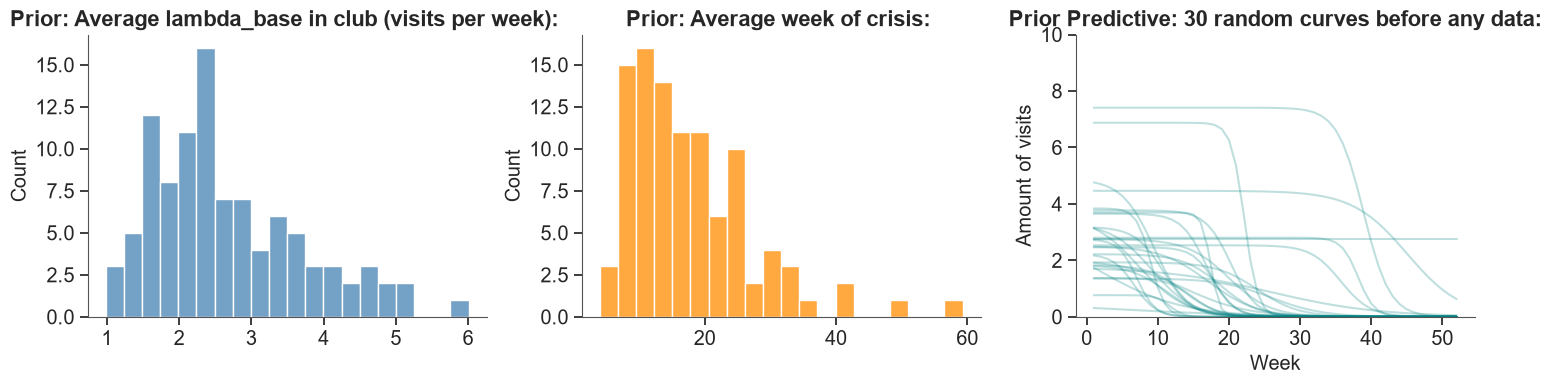

In [5]:
prior_predictive = Predictive(gym_habit_model, num_samples=100)
prior_samples = prior_predictive(jax.random.PRNGKey(42), data=model_data, include_obs=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(np.exp(prior_samples["mu_lambda"]), bins=20, color="steelblue", ax=axes[0])
axes[0].set_title("Prior: Average lambda_base in club (visits per week): ")

sns.histplot(np.exp(prior_samples["mu_tau"]), bins=20, color="darkorange", ax=axes[1])
axes[1].set_title("Prior: Average week of crisis: ")

weeks_grid = np.arange(1, 53)
for s in range(30):
    lb = float(prior_samples["lambda_base"][s, 0])
    t0 = float(prior_samples["tau"][s, 0])
    gm = float(prior_samples["gamma"][s, 0])
    curve = lb / (1.0 + np.exp(np.clip(gm * (weeks_grid - t0), -20, 20)))
    axes[2].plot(weeks_grid, curve, color="teal", alpha=0.25)

axes[2].set_title("Prior Predictive: 30 random curves before any data:")
axes[2].set_xlabel("Week")
axes[2].set_ylabel("Amount of visits")
axes[2].set_ylim(0, 10)

plt.tight_layout()
plt.show()

In [6]:
nuts_kernel = NUTS(gym_habit_model, target_accept_prob=0.85)
mcmc = MCMC(
    nuts_kernel,
    num_warmup=400,
    num_samples=400,
    num_chains=4,
    progress_bar=True
)

mcmc.run(jax.random.PRNGKey(123), data=model_data, include_obs=True)
idata = az.from_numpyro(mcmc)

global_vars = [
    "mu_lambda", "beta_lambda_dist", "beta_lambda_group", "sigma_lambda",
    "mu_tau", "beta_tau_dist", "beta_tau_friends", "beta_tau_group",
    "beta_tau_partner", "beta_tau_age", "beta_tau_returning", "sigma_tau",
    "mu_gamma", "beta_gamma_group", "beta_gamma_friends", "sigma_gamma",
    "vacation_prob",
]

summary_df = az.summary(idata, var_names=global_vars, ci_prob=0.90)
display(summary_df)

  0%|          | 0/800 [00:00<?, ?it/s]

  0%|          | 0/800 [00:00<?, ?it/s]

  0%|          | 0/800 [00:00<?, ?it/s]

  0%|          | 0/800 [00:00<?, ?it/s]

,mean,sd,eti90_lb,eti90_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_lambda,0.937,0.0211,0.9,0.97,577,666,1.00,0.00088,0.00046
beta_lambda_dist,-0.109,0.0187,-0.14,-0.08,631,934,1.00,0.00075,0.00041
beta_lambda_group,0.196,0.057,0.1,0.29,476,661,1.00,0.0026,0.0015
sigma_lambda,0.295,0.0141,0.27,0.32,470,630,1.01,0.00065,0.00037
mu_tau,2.934,0.039,2.9,3,130,239,1.02,0.0034,0.0012
beta_tau_dist,-0.343,0.03,-0.39,-0.3,275,465,1.02,0.0018,0.00086
beta_tau_friends,0.353,0.054,0.27,0.44,164,321,1.02,0.0042,0.0018
beta_tau_group,0.43,0.089,0.28,0.58,285,504,1.02,0.0052,0.0027
beta_tau_partner,0.126,0.053,0.041,0.21,183,342,1.01,0.0039,0.0016
beta_tau_age,0.161,0.025,0.12,0.2,242,375,1.01,0.0016,0.00084


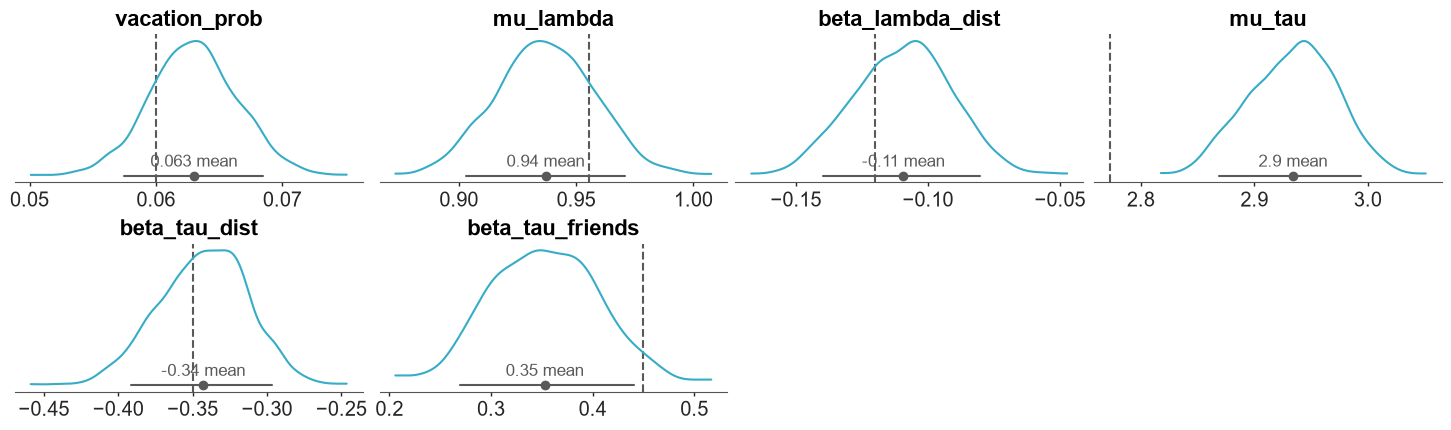

In [7]:
TRUE_PARAMS_FLAT = {
    "vacation_prob": 0.06,
    "mu_lambda": np.log(2.6),
    "beta_lambda_dist": -0.12,
    "mu_tau": np.log(16.0),
    "beta_tau_dist": -0.35,
    "beta_tau_friends": 0.45,
}

pc = azp.plot_dist(
    idata,
    var_names=list(TRUE_PARAMS_FLAT.keys()),
)

azp.add_lines(
    pc,
    values=xr.Dataset(TRUE_PARAMS_FLAT),
    color="black",
    linestyle="--"
)

pc.show()

In [8]:
start_time = time.time()

guide = AutoNormal(gym_habit_model)

optimizer = optim.Adam(step_size=0.01)
svi = SVI(gym_habit_model, guide, optimizer, loss=Trace_ELBO())

svi_result = svi.run(jax.random.PRNGKey(42), num_steps=5000, data=model_data, include_obs=True)

guide_samples = Predictive(guide, params=svi_result.params, num_samples=1000)(
    jax.random.PRNGKey(1), data=model_data, include_obs=True
)

det_samples = Predictive(
    gym_habit_model,
    posterior_samples=guide_samples,
    return_sites=["lambda_base", "tau", "gamma"],
)(jax.random.PRNGKey(2), data=model_data, include_obs=True)

svi_samples = {**guide_samples, **det_samples}

svi_time = time.time() - start_time
print(f"SVI training finished in: {svi_time:.2f} seconds")

posterior_dict = {k: np.expand_dims(np.asarray(v), 0) for k, v in svi_samples.items()}
idata_svi = azb.from_dict({"posterior": posterior_dict})

summary_svi = azs.summary(
    idata_svi,
    var_names=["mu_lambda", "mu_tau", "vacation_prob", "beta_tau_friends"],
    ci_prob=0.90
)
display(summary_svi)

100%|██████████| 5000/5000 [00:18<00:00, 274.49it/s, init loss: 312104.1562, avg. loss [4751-5000]: 29433.1172]


SVI training finished in: 59.20 seconds


,mean,sd,eti90_lb,eti90_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_lambda,0.9389,0.0066,0.93,0.95,914,772,nan,0.00022,0.00016
mu_tau,2.9825,0.0045,3,3,991,910,nan,0.00014,0.0001
vacation_prob,0.0654,0.0031,0.061,0.071,956,946,nan,0.0001,7.2e-05
beta_tau_friends,0.3463,0.0064,0.34,0.36,861,783,nan,0.00022,0.00014


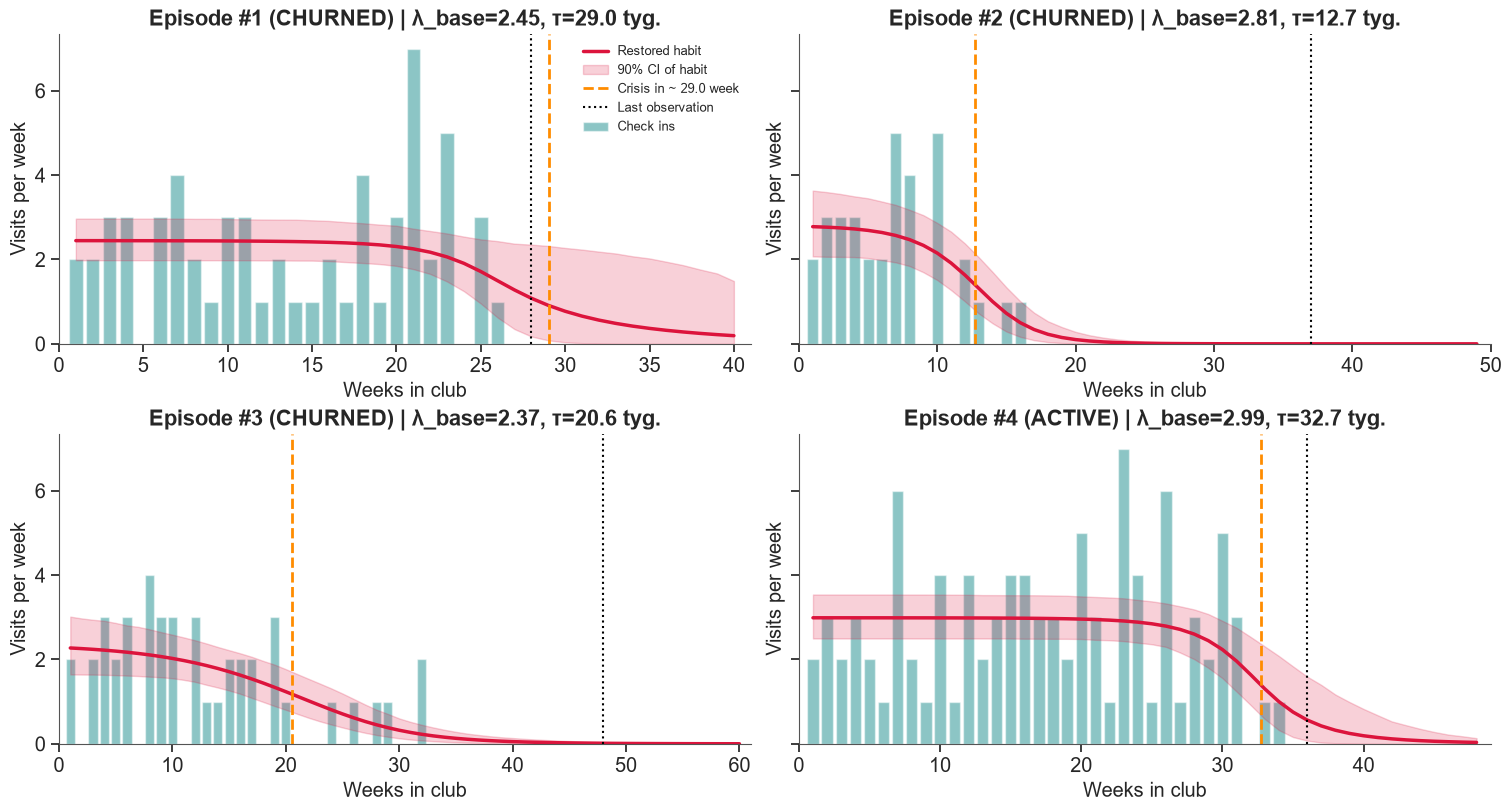

In [9]:
posterior_samples = mcmc.get_samples() if "mcmc" in locals() else svi_samples

episodes_df["lambda_base_est"] = np.asarray(posterior_samples["lambda_base"]).mean(axis=0)
episodes_df["tau_est"] = np.asarray(posterior_samples["tau"]).mean(axis=0)
episodes_df["gamma_est"] = np.asarray(posterior_samples["gamma"]).mean(axis=0)

sample_eps = [1, 2, 3, 4]
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharey=True)

for ax, ep_id in zip(axes.flat, sample_eps):
    ep_row = episodes_df[episodes_df["episode_id"] == ep_id].iloc[0]
    ep_idx = int(ep_row["ep_idx"])
    ep_data = weekly_grid_df[weekly_grid_df["episode_id"] == ep_id]

    max_t = int(ep_row["observed_weeks"]) + 12
    t_grid = np.arange(1, max_t + 1)

    lb_s = np.asarray(posterior_samples["lambda_base"][:, ep_idx])[:, None]
    tau_s = np.asarray(posterior_samples["tau"][:, ep_idx])[:, None]
    gam_s = np.asarray(posterior_samples["gamma"][:, ep_idx])[:, None]

    curves = lb_s / (1.0 + np.exp(np.clip(gam_s * (t_grid[None, :] - tau_s), -20, 20)))
    mean_curve = curves.mean(axis=0)
    ci_low = np.percentile(curves, 5, axis=0)
    ci_high = np.percentile(curves, 95, axis=0)

    ax.bar(ep_data["t"], ep_data["visits"], color="teal", alpha=0.45, width=0.8, label="Check ins")
    ax.plot(t_grid, mean_curve, color="crimson", linewidth=2.5, label="Restored habit")
    ax.fill_between(t_grid, ci_low, ci_high, color="crimson", alpha=0.2, label="90% CI of habit")

    ax.axvline(ep_row["tau_est"], color="darkorange", linestyle="--", linewidth=2, label=f"Crisis in ~ {ep_row['tau_est']:.1f} week")
    ax.axvline(ep_row["observed_weeks"], color="black", linestyle=":", linewidth=1.5, label="Last observation")

    ax.set_title(
        f"Episode #{ep_id} ({ep_row['final_status'].upper()}) | "
        f"λ_base={ep_row['lambda_base_est']:.2f}, τ={ep_row['tau_est']:.1f} tyg."
    )
    ax.set_xlabel("Weeks in club")
    ax.set_ylabel("Visits per week")
    ax.set_xlim(0, max_t + 1)

axes[0, 0].legend(loc="upper right", fontsize=9)
plt.show()

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

contracts_df = pd.read_csv(Path("data/synthetic_raw/contracts.csv"))
contracts_df["start_date"] = pd.to_datetime(contracts_df["start_date"])
contracts_df["end_date"] = pd.to_datetime(contracts_df["end_date"])

episodes_df["episode_start"] = pd.to_datetime(episodes_df["episode_start"])
episodes_df["contract_end"] = pd.to_datetime(episodes_df["contract_end"])

contracts_with_ep = contracts_df.merge(
    episodes_df[[
        "episode_id", "member_id", "episode_start", "contract_end",
        "lambda_base_est", "tau_est", "gamma_est"
    ]],
    on="member_id",
    how="inner",
)
contracts_with_ep = contracts_with_ep[
    (contracts_with_ep["start_date"] >= contracts_with_ep["episode_start"])
    & (contracts_with_ep["end_date"] <= contracts_with_ep["contract_end"])
].copy()

contracts_with_ep["t_decision"] = (
    (contracts_with_ep["end_date"] - contracts_with_ep["episode_start"]).dt.days // 7
).clip(lower=1)

exp_term = np.clip(
    contracts_with_ep["gamma_est"] * (contracts_with_ep["t_decision"] - contracts_with_ep["tau_est"]),
    -20.0, 20.0
)
contracts_with_ep["lambda_at_decision"] = contracts_with_ep["lambda_base_est"] / (1.0 + np.exp(exp_term))
contracts_with_ep["drop_ratio_at_decision"] = 1.0 - (
    contracts_with_ep["lambda_at_decision"] / contracts_with_ep["lambda_base_est"]
)
contracts_with_ep["long_contract_shock"] = (contracts_with_ep["duration_months"] >= 6).astype(int)

hist_decisions = contracts_with_ep[contracts_with_ep["status"].isin(["churned", "renewed"])].copy()
hist_decisions["y_churn"] = (hist_decisions["status"] == "churned").astype(int)

features_B = ["lambda_at_decision", "drop_ratio_at_decision", "long_contract_shock"]
X_hist = hist_decisions[features_B]
y_hist = hist_decisions["y_churn"]

clf_churn = LogisticRegression(C=np.inf)
clf_churn.fit(X_hist, y_hist)

pred_probs_hist = clf_churn.predict_proba(X_hist)[:, 1]

active_df = episodes_df[episodes_df["final_status"] == "active"].copy()

exp_today = np.clip(active_df["gamma_est"] * (active_df["observed_weeks"] - active_df["tau_est"]), -20.0, 20.0)
active_df["lambda_today"] = active_df["lambda_base_est"] / (1.0 + np.exp(exp_today))
active_df["drop_ratio_today"] = 1.0 - (active_df["lambda_today"] / active_df["lambda_base_est"])
active_df["long_contract_shock"] = (active_df["last_duration_months"] >= 6).astype(int)

X_active_today = pd.DataFrame({
    "lambda_at_decision": active_df["lambda_today"],
    "drop_ratio_at_decision": active_df["drop_ratio_today"],
    "long_contract_shock": active_df["long_contract_shock"],
})
active_df["prob_churn_current"] = clf_churn.predict_proba(X_active_today)[:, 1].round(3)
active_df["revenue_at_risk_pln"] = (active_df["prob_churn_current"] * active_df["avg_monthly_price"]).round(2)

conditions = [
    active_df["drop_ratio_today"] > 0.75,
    (active_df["drop_ratio_today"] >= 0.25) & (active_df["drop_ratio_today"] <= 0.75),
    (active_df["weeks_to_contract_end"] <= 4) & (active_df["drop_ratio_today"] < 0.25),
]
choices = [
    "3. Zombie zone (Lost habit >75%)",
    "1. Behavioral alarm (Diminishing habit 25-75%)",
    "2. Hot window (Healthy habit, end of contract <=4 wks)",
]
active_df["segment"] = np.select(conditions, choices, default="4. Strong base (Healthy habit)")

segment_summary = (
    active_df.groupby("segment", as_index=False)
    .agg(
        client_amount=("member_id", "count"),
        average_lambda=("lambda_today", "mean"),
        average_drop_ratio=("drop_ratio_today", "mean"),
        average_churn_risk=("prob_churn_current", "mean"),
        revenue_at_risk=("revenue_at_risk_pln", "sum"),
    )
    .sort_values("segment")
)

urgent_clients = active_df[active_df["segment"].str.startswith("1.")].sort_values(
    "drop_ratio_today", ascending=False
)

print(f"Historical windows: {len(hist_decisions)} | ROC AUC: {roc_auc_score(y_hist, pred_probs_hist):.3f} | Brier: {brier_score_loss(y_hist, pred_probs_hist):.3f}")
display(segment_summary.round(2))
display(urgent_clients[[
    "episode_id", "member_id", "observed_weeks", "weeks_to_contract_end",
    "lambda_base_est", "lambda_today", "drop_ratio_today", "prob_churn_current", "revenue_at_risk_pln"
]].round(2))

Historical windows: 1219 | ROC AUC: 0.925 | Brier: 0.088


,segment,client_amount,average_lambda,average_drop_ratio,average_churn_risk,revenue_at_risk
0,1. Behavioral alarm (Diminishing habit 25-75%),16,1.51,0.50,0.60,1511.32
1,"2. Hot window (Healthy habit, end of contract ...",17,3.00,0.03,0.12,371.21
2,3. Zombie zone (Lost habit >75%),74,0.13,0.96,0.94,10868.03
3,4. Strong base (Healthy habit),48,3.14,0.02,0.22,1646.65


,episode_id,member_id,observed_weeks,weeks_to_contract_end,lambda_base_est,lambda_today,drop_ratio_today,prob_churn_current,revenue_at_risk_pln
186,187,172,54,6,2.78,0.77,0.72,0.86,160.07
313,314,282,16,32,3.24,0.96,0.70,0.83,115.23
156,157,145,30,17,2.41,0.75,0.69,0.85,165.09
34,35,34,39,3,2.42,0.79,0.67,0.55,106.15
499,500,448,51,1,4.20,1.64,0.61,0.70,100.12
485,486,436,41,7,2.99,1.24,0.58,0.76,105.08
453,454,407,20,4,2.28,1.02,0.55,0.78,131.99
136,137,127,37,2,4.28,1.94,0.55,0.27,44.99
486,487,437,39,9,2.51,1.15,0.54,0.76,105.22
66,67,64,68,36,4.70,2.55,0.46,0.45,64.07


=== Episode 4 results ===


,episode_id,member_id,observed_weeks,lambda_base_est,tau_est,lambda_today,drop_ratio_today,segment
3,4,4,36,2.99,32.75,0.46,0.85,3. Zombie zone (Lost habit >75%)


Real parameters of episode 4:


,member_id,_true_lambda_base,_true_tau,_true_gamma
3,4,2.88,32.1,0.48


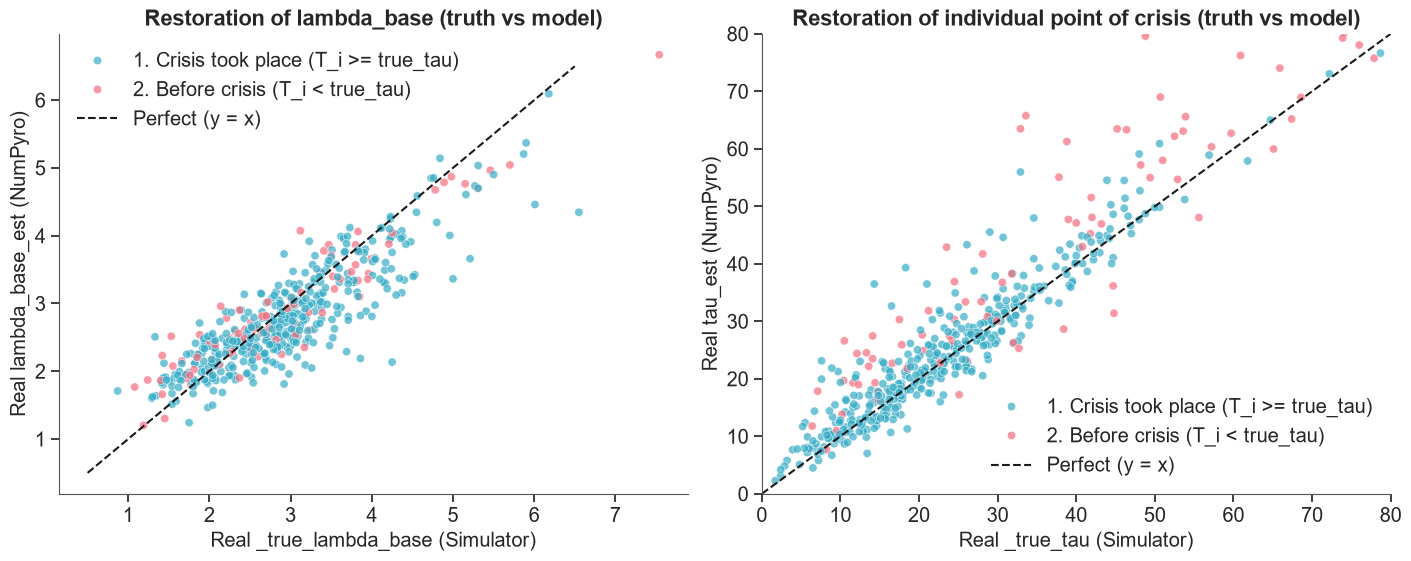

In [16]:
gt_df = pd.read_csv(Path("data/synthetic_raw/ground_truth_members.csv"))

eval_ind_df = (
    episodes_df[episodes_df["member_episode_num"] == 1]
    .merge(gt_df, on="member_id", how="inner")
    .copy()
)

ep4_info = active_df[active_df["episode_id"] == 4][
    ["episode_id", "member_id", "observed_weeks", "lambda_base_est", "tau_est", "lambda_today", "drop_ratio_today", "segment"]
]
print("=== Episode 4 results ===")
display(ep4_info.round(2))
print("Real parameters of episode 4:")
display(gt_df[gt_df["member_id"] == 4][["member_id", "_true_lambda_base", "_true_tau", "_true_gamma"]].round(2))

eval_ind_df["crisis_observed"] = np.where(
    eval_ind_df["observed_weeks"] >= eval_ind_df["_true_tau"],
    "1. Crisis took place (T_i >= true_tau)",
    "2. Before crisis (T_i < true_tau)",
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.scatterplot(
    data=eval_ind_df, x="_true_lambda_base", y="lambda_base_est",
    hue="crisis_observed", alpha=0.7, ax=axes[0]
)
axes[0].plot([0.5, 6.5], [0.5, 6.5], "k--", linewidth=1.5, label="Perfect (y = x)")
axes[0].set_title("Restoration of lambda_base (truth vs model)")
axes[0].set_xlabel("Real _true_lambda_base (Simulator)")
axes[0].set_ylabel("Real lambda_base_est (NumPyro)")
axes[0].legend()

sns.scatterplot(
    data=eval_ind_df, x="_true_tau", y="tau_est",
    hue="crisis_observed", alpha=0.7, ax=axes[1]
)
axes[1].plot([0, 80], [0, 80], "k--", linewidth=1.5, label="Perfect (y = x)")
axes[1].set_xlim(0, 80)
axes[1].set_ylim(0, 80)
axes[1].set_title("Restoration of individual point of crisis (truth vs model)")
axes[1].set_xlabel("Real _true_tau (Simulator)")
axes[1].set_ylabel("Real tau_est (NumPyro)")
axes[1].legend()

plt.show()